# **Step 8 – Interpretación de los patrones**
**Proyecto TA – Análisis de Datos (1INF03, 2026-2) – Equipo E10**

> *KDD, paso 8 (Fayyad, Piatetsky-Shapiro y Smyth, 1996):* «Interpreting mined patterns: possibly return to any steps. Also involve visualization of the extracted patterns/models, or visualization of the data given the extracted models.»

Entrada: `datos/4_resultados/step7_puntajes.csv`, `step7_cargas_pca.csv`, los z OMS por niño (`step4_ninos.csv`) y las cifras de los pasos anteriores.

Contenido:
1. qué significa cada cuadrante;
2. qué explican las dimensiones (edad, UPE, sexo) y si se relacionan con el estado nutricional;
3. **evaluación comparativa de todos los modelos construidos**;
4. el recorrido del proyecto: a qué pasos se volvió y por qué.

## Librerías y datos

In [1]:
import warnings; warnings.filterwarnings("ignore")
import json
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy.stats import spearmanr, kruskal, mannwhitneyu
TRA, RES, FIG = Path("../datos/3_transformados"), Path("../datos/4_resultados"), Path("../figuras")
sns.set_theme(style="whitegrid"); plt.rcParams["figure.dpi"] = 110
at = pd.read_csv(RES/"step7_puntajes.csv", sep="|")
cargas = pd.read_csv(RES/"step7_cargas_pca.csv", sep="|", index_col=0)
c6, c4, a6 = (json.load(open(RES/f"cifras_{k}.json")) for k in ["step6", "step4", "anexo6"])
PRIORIDAD = "Prioridad: larga permanencia, baja atención"
print("Niños:", len(at))

Niños: 158


## 1. ¿Qué caracteriza a cada cuadrante?
Se resume cada cuadrante con las variables originales (no con los puntajes), para que la lectura sea directa.

                                             niños  edad  tiempo_hogar_meses  pct_definitiva  pct_sin_soporte  pct_sin_pti  pct_salud_mental  pct_varones
cuadrante                                                                                                                                                
Larga permanencia, atención activa              20  14.0               104.2            65.0             25.0         85.0              65.0         55.0
Prioridad: larga permanencia, baja atención     51  12.1                95.6            27.5             84.3         62.7               0.0         45.1
Reciente, atención activa                       39   8.6                46.4             0.0              0.0         15.4              12.8         71.8
Reciente, baja atención                         48   8.5                47.5             0.0             33.3         12.5               0.0         54.2


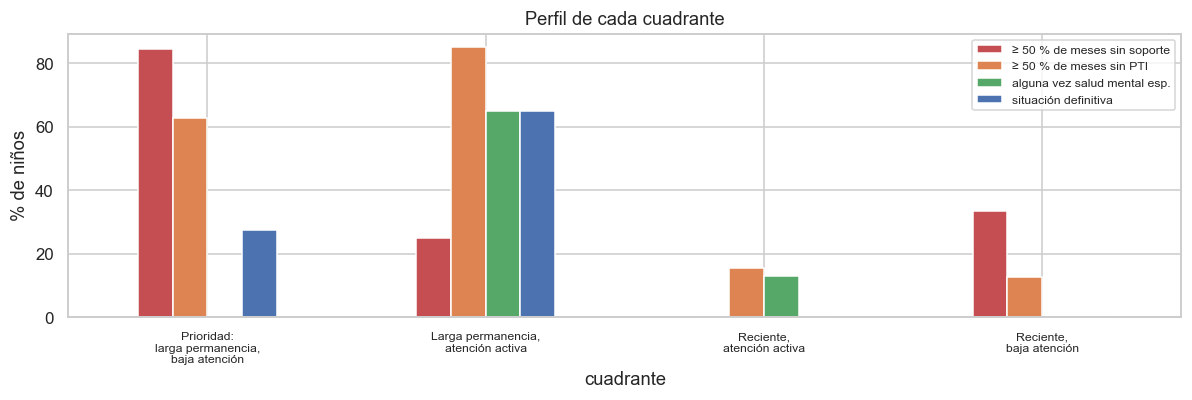

In [2]:
cuad = at.groupby("cuadrante").agg(niños=("id_nna", "size"), edad=("edad", "mean"), tiempo_hogar_meses=("tiempo_hogar", "mean"),
                                   pct_definitiva=("legal_definitiva", "mean"),
                                   pct_sin_soporte=("p_sin_soporte", lambda s: (s >= .5).mean()),
                                   pct_sin_pti=("p_pti_no_tiene", lambda s: (s >= .5).mean()),
                                   pct_salud_mental=("p_salud_mental", lambda s: (s > 0).mean()),
                                   pct_varones=("sexo_m", "mean"))
for c in [c for c in cuad.columns if c.startswith("pct")]: cuad[c] = 100 * cuad[c]
cuad = cuad.round(1); print(cuad.to_string())
orden_c = [PRIORIDAD, "Larga permanencia, atención activa", "Reciente, atención activa", "Reciente, baja atención"]
fig, ax = plt.subplots(figsize=(11, 3.8))
cuad.loc[orden_c, ["pct_sin_soporte", "pct_sin_pti", "pct_salud_mental", "pct_definitiva"]].plot(kind="bar", ax=ax, color=["#C44E52", "#DD8452", "#55A868", "#4C72B0"])
ax.set_xticklabels([c.replace(": ", ":\n").replace(", ", ",\n") for c in orden_c], rotation=0, fontsize=8); ax.set_ylabel("% de niños")
ax.legend(["≥ 50 % de meses sin soporte", "≥ 50 % de meses sin PTI", "alguna vez salud mental esp.", "situación definitiva"], fontsize=8)
ax.set_title("Perfil de cada cuadrante"); plt.tight_layout(); plt.savefig(FIG/"step8_cuadrantes.png", bbox_inches="tight"); plt.show()

**Interpretación.**
- **Prioridad (51 niños, 32 %):** llevan en promedio 96 meses en el hogar (8 años); el **84 %** pasó la mitad de los meses o más **sin ningún soporte psicoemocional**, el **63 %** sin PTI y **ninguno** recibió salud mental especializada.
- **Larga permanencia con atención activa (20):** tiempo parecido en el hogar (104 meses), pero el 65 % recibe salud mental especializada y solo el 25 % pasa la mayoría de meses sin soporte.
- **Recientes (39 + 48):** unos 4 años en el hogar; casi todos tienen PTI y la diferencia entre ellos es si reciben o no soporte.

**Lectura central:** a **igual permanencia**, unos niños reciben atención y otros casi ninguna. Esa diferencia no se ve en la ficha mes a mes; aparece al combinar las variables (Step 7).

## 2. ¿Qué explican las dimensiones?
La edad, la UPE, el sexo y el estado nutricional **no entraron** al PCA. Se mide su relación con cada dimensión: Spearman para variables numéricas, Kruskal-Wallis para la UPE y Mann-Whitney para el sexo.

In [3]:
nut = pd.read_csv(TRA/"step4_ninos.csv", sep="|")[["id_nna", "z_imc", "z_talla", "cat_imc"]]
an = at.merge(nut, on="id_nna")
rel = []
for d in ["permanencia", "intensidad"]:
    r, p = spearmanr(at[d], at["edad"]); rel.append({"dimensión": d, "variable": "edad", "estadístico": round(r, 2), "p": p})
    rel.append({"dimensión": d, "variable": "UPE", "estadístico": np.nan, "p": kruskal(*[g[d] for _, g in at.groupby("upe")])[1]})
    rel.append({"dimensión": d, "variable": "sexo", "estadístico": np.nan, "p": mannwhitneyu(at.loc[at.sexo_m == 1, d], at.loc[at.sexo_m == 0, d])[1]})
    for z in ["z_imc", "z_talla"]:
        r, p = spearmanr(an[d], an[z]); rel.append({"dimensión": d, "variable": z, "estadístico": round(r, 2), "p": p})
rel = pd.DataFrame(rel); rel["p"] = rel["p"].round(4); print(rel.to_string(index=False))
upe = at.groupby("upe")[["permanencia", "intensidad"]].mean().round(2); upe["niños"] = at["upe"].value_counts(); print(); print(upe.to_string())
nut_cuad = an.groupby("cuadrante").agg(niños_medidos=("id_nna", "size"), pct_exceso=("cat_imc", lambda s: 100 * s.isin(["Sobrepeso", "Obesidad"]).mean()),
                                       pct_talla_baja=("z_talla", lambda s: 100 * (s < -2).mean())).round(1)
print(); print(nut_cuad.to_string())

  dimensión variable  estadístico      p
permanencia     edad         0.51 0.0000
permanencia      UPE          NaN 0.0000
permanencia     sexo          NaN 0.4752
permanencia    z_imc         0.03 0.7266
permanencia  z_talla        -0.01 0.8949
 intensidad     edad        -0.15 0.0676
 intensidad      UPE          NaN 0.2593
 intensidad     sexo          NaN 0.0135
 intensidad    z_imc        -0.01 0.9210
 intensidad  z_talla        -0.02 0.7980

                   permanencia  intensidad  niños
upe                                              
Lima                      0.64       -0.05     38
Lima Este                 0.09       -0.24     44
Lima Norte-Callao        -0.43        0.02     61
Lima Sur                 -1.07        0.54     12
Otra                      3.47        1.42      3



                                             niños_medidos  pct_exceso  pct_talla_baja
cuadrante                                                                             
Larga permanencia, atención activa                      19        52.6            21.1
Prioridad: larga permanencia, baja atención             40        45.0            15.0
Reciente, atención activa                               29        34.5            24.1
Reciente, baja atención                                 47        40.4            12.8


**Interpretación.**
- **Permanencia:** se relaciona con la edad (ρ = 0,51), como era de esperar, y **difiere entre UPE** (*p* < 0,001). La unidad de protección a cargo se asocia con cuánto tiempo y con qué situación legal permanece el niño: es una pista para revisar con la institución, no una conclusión causal.
- **Intensidad psicosocial:** **no depende de la edad** (*p* = 0,07) **ni de la UPE** (*p* = 0,26), pero **sí difiere por sexo** (*p* = 0,01): los varones tienen más intensidad (+0,18 frente a −0,22 en las mujeres), en parte porque registran más discapacidad y más atención en salud mental especializada. Fuera de eso, quién recibe atención especializada no se explica por las características registradas del niño.
- **Estado nutricional:** ninguna dimensión se relaciona con el z de IMC ni con el de talla (todos *p* > 0,7). El exceso de peso está entre 35 % y 53 % en todos los cuadrantes. El problema nutricional es **generalizado** en la institución y no depende del tipo de atención psicosocial. La literatura documenta retraso del crecimiento en niños institucionalizados (Johnson y Gunnar, 2011); aquí, además de talla baja (17 %), predomina el exceso de peso (≈ 40 %).

## 3. Evaluación comparativa de los modelos construidos
Se comparan todos los enfoques con los mismos criterios: ¿encuentran estructura real (mejor que el azar)?, ¿es estable?, ¿es **no trivial** (no repite una variable ya registrada)?, ¿es útil para la institución?

In [4]:
comp = pd.DataFrame([
    {"modelo": "Clasificación de la etiqueta de la ficha (avance)", "estructura real": "sí (AUC 0,85; p = 0,01)", "estable": "sí",
     "no trivial": "no: imita una etiqueta manual con rezago", "útil": "baja"},
    {"modelo": "Clustering nutricional, z OMS (anexo)", "estructura real": f"no (Hopkins {c4['hopkins']:.2f} = normal; BIC k = 1)", "estable": f"débil (ARI {a6['ari_elegido']:.2f})",
     "no trivial": f"parcial (ARI {a6['ari_regla_oms']:.2f} con cortes OMS)", "útil": "baja"},
    {"modelo": "Clustering de la atención (K-Means, Ward, Gower, LCA)", "estructura real": f"no frente a nula permutada (p = {c6['p_permutada_mas_estable']:.2f})",
     "estable": f"límite (ARI {c6['ari_mas_estable']:.2f})", "no trivial": f"no: repite la situación legal (ARI {c6['ari_con_legal']:.2f})", "útil": "baja"},
    {"modelo": "Clustering de secuencias mes a mes", "estructura real": "sí", "estable": "sí",
     "no trivial": f"no: repite el estado predominante (ARI {c6['secuencias_ari_modal']:.2f})", "útil": "baja"},
    {"modelo": "PCA de la atención (elegido)", "estructura real": f"sí: {c6['pca_componentes']} componentes superan el análisis paralelo",
     "estable": f"sí (Tucker {min(c6['tucker']):.2f}–{max(c6['tucker']):.2f})", "no trivial": "sí: combina 10 variables con pesos aprendidos", "útil": "alta: índice de prioridad"}])
comp.to_csv(RES/"step8_comparacion_modelos.csv", sep="|", index=False); comp

,modelo,estructura real,estable,no trivial,útil
0,Clasificación de la etiqueta de la ficha (avance),"sí (AUC 0,85; p = 0,01)",sí,no: imita una etiqueta manual con rezago,baja
1,"Clustering nutricional, z OMS (anexo)",no (Hopkins 0.64 = normal; BIC k = 1),débil (ARI 0.70),parcial (ARI 0.31 con cortes OMS),baja
2,"Clustering de la atención (K-Means, Ward, Gowe...",no frente a nula permutada (p = 0.09),límite (ARI 0.75),no: repite la situación legal (ARI 0.75),baja
3,Clustering de secuencias mes a mes,sí,sí,no: repite el estado predominante (ARI 0.99),baja
4,PCA de la atención (elegido),sí: 2 componentes superan el análisis paralelo,sí (Tucker 0.86–0.93),sí: combina 10 variables con pesos aprendidos,alta: índice de prioridad


**Interpretación.** El modelo con la métrica más alta (AUC 0,85) no es el mejor: reproducía una etiqueta manual que no cambió en 19 meses. Los modelos de clustering encuentran grupos que la ficha **ya registra** (situación legal o estado predominante), y la nutrición no forma grupos. El **PCA** es el único que cumple los cuatro criterios.

## 4. El recorrido del proyecto (volver a pasos anteriores)
Fayyad et al. (1996) señalan que interpretar puede obligar a «volver a cualquier paso». Este proyecto lo hizo cuatro veces:

| Iteración | Pasos revisados | Qué se aprendió | Decisión |
|---|---|---|---|
| 1. Clasificación (avance) | 1, 5, 6 | Funciona (AUC 0,85), pero imita una etiqueta manual con rezago | Cambiar a una tarea no supervisada |
| 2. Clustering nutricional | 3, 4, 6 | Los z OMS son un continuo sin grupos | Buscar estructura en otra fuente: la ficha |
| 3. Clustering de la atención | 3, 4, 6 | Los grupos repiten la situación legal | Probar reducción de dimensiones |
| 4. PCA de la atención | 6, 7 | Dos dimensiones reales, estables y no triviales | **Modelo final** |

## Verificación y cifras de este notebook

In [5]:
assert cuad.loc[PRIORIDAD, "niños"] == 51 and cuad.loc[PRIORIDAD, "pct_sin_soporte"] == 84.3 and cuad.loc[PRIORIDAD, "pct_salud_mental"] == 0
r_ = rel.set_index(["dimensión", "variable"])
assert r_.loc[("permanencia", "edad"), "estadístico"] == 0.51 and r_.loc[("permanencia", "UPE"), "p"] < 0.001 and r_.loc[("intensidad", "UPE"), "p"] > 0.05 and r_.loc[("intensidad", "sexo"), "p"] < 0.05
assert (r_.loc[[("permanencia", "z_imc"), ("permanencia", "z_talla"), ("intensidad", "z_imc"), ("intensidad", "z_talla")], "p"] > 0.7).all()
cifras = {"cuadrantes": cuad["niños"].to_dict(), "prioridad_pct_sin_soporte": float(cuad.loc[PRIORIDAD, "pct_sin_soporte"]),
          "prioridad_pct_sin_pti": float(cuad.loc[PRIORIDAD, "pct_sin_pti"]), "prioridad_tiempo_hogar": float(cuad.loc[PRIORIDAD, "tiempo_hogar_meses"]),
          "rho_permanencia_edad": float(r_.loc[("permanencia", "edad"), "estadístico"]), "p_permanencia_upe": float(r_.loc[("permanencia", "UPE"), "p"]),
          "p_intensidad_upe": float(r_.loc[("intensidad", "UPE"), "p"]), "p_intensidad_edad": float(r_.loc[("intensidad", "edad"), "p"]), "p_intensidad_sexo": float(r_.loc[("intensidad", "sexo"), "p"])}
json.dump(cifras, open(RES/"cifras_step8.json", "w"), indent=1); cifras

{'cuadrantes': {'Larga permanencia, atención activa': 20,
  'Prioridad: larga permanencia, baja atención': 51,
  'Reciente, atención activa': 39,
  'Reciente, baja atención': 48},
 'prioridad_pct_sin_soporte': 84.3,
 'prioridad_pct_sin_pti': 62.7,
 'prioridad_tiempo_hogar': 95.6,
 'rho_permanencia_edad': 0.51,
 'p_permanencia_upe': 0.0,
 'p_intensidad_upe': 0.2593,
 'p_intensidad_edad': 0.0676,
 'p_intensidad_sexo': 0.0135}